In [1]:
import os
import sys
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..', 'utility')))
os.environ["CUDA_VISIBLE_DEVICES"] = "0,1"  
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '1'  # or any {'0', '1', '2'}

from sklearn.preprocessing      import MinMaxScaler
from keras.models               import Model
from keras.layers               import Input, Conv1D, MaxPooling1D, UpSampling1D, Dense, Flatten, Reshape, ZeroPadding1D, Concatenate, Lambda, Multiply, Minimum, Maximum, LSTM, Masking
from keras.layers               import GlobalAveragePooling1D, RepeatVector
from keras.constraints          import NonNeg
from preProcessingDataTurbofan  import PreProcessData
from matpilotDraw               import MatPlot

import tensorflow           as tf
import numpy                as np
import pandas               as pd
import matplotlib.pyplot    as plt
import random
import warnings

seedNumber  = 4
hiSelectionMode = "linear"
drawTrajectories = 300


warnings.filterwarnings('ignore') 
tf.random.set_seed(seedNumber)
np.random.seed(seedNumber)
random.seed(seedNumber)

useRUL          = True
epochTrain      = 20
sysEpoch        = 20
prePro          = PreProcessData()
# -----------------------------
# Load and prepare data
# -----------------------------
column_names = [    "id",   "cycle",    "setting1", "setting2", "`setting3`",
                    "s1",   "s2",       "s3",       "s4",       "s5",       "s6",   "s7",   "s8",   "s9",   "s10",
                    "s11",  "s12",      "s13",      "s14",      "s15",      "s16",  "s17",  "s18",  "s19",  "s20",  "s21"
                ]
sensors_used        = ['s2','s3','s4','s7','s8','s9','s11','s12','s13','s14','s15','s17','s20','s21']
# sensors_used        = ['s1', 's2','s3','s4',"s5", "s6",'s7','s8','s9',"s10",'s11','s12','s13','s14','s15',"s16",'s17',"s18","s19",'s20','s21']
df                  = pd.read_csv('~/Desktop/Dropbox/codeData/turbofanEngines/data/df_train.txt', delim_whitespace=True, header=None, names=column_names)

df["rul"]           = df.groupby('id',sort=False)['cycle'].transform(lambda x: x.max() - x)         # Get RUL

# print(df.shape)
df[sensors_used]    = df.groupby("id")[sensors_used].apply(lambda g: prePro.flip2DownPandasMultipleCol(g, g.columns))

# print(df.shape)
# sameLengthDf    = PreProcessData.padDataForTheSameTrajectoryLength(df)  
# -----------------------------
# Initialize variables
# -----------------------------


2025-04-24 14:52:41.098837: E tensorflow/stream_executor/cuda/cuda_blas.cc:2981] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-04-24 14:52:41.646789: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer.so.7'; dlerror: libnvinfer.so.7: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: :/home/duc-an/anaconda3/envs/tensorflow2.10.0/lib/
2025-04-24 14:52:41.646842: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer_plugin.so.7'; dlerror: libnvinfer_plugin.so.7: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: :/home/duc-an/anaconda3/envs/tensorflow2.10.0/lib/
2025-04-24 14:52:41.646845: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Cannot dlopen some TensorRT libraries. If you would like to use Nvidia GPU with TensorRT, plea

In [2]:
# id =1
# drawData = df[df["id"]==id]
# plot = MatPlot()
# for sensor in sensors_used:
#     plot.draw1D(drawData[sensor], title=sensor)

(17731, 30, 14)
(17731, 30, 1)
The shape of last layer encoder is (None, 8, 16)
---------------------------
(14,)
(None, 30, 14)
---------------------------
['reconstruction', 'RUL_Output']
['ss_prob', 'recon_loss']
Epoch 1/20


2025-04-24 14:52:51.282723: W tensorflow/stream_executor/gpu/asm_compiler.cc:80] Couldn't get ptxas version string: INTERNAL: Couldn't invoke ptxas --version
2025-04-24 14:52:51.283004: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] INTERNAL: Failed to launch ptxas
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.


125/125 [==============================] - 7s 16ms/step - loss: 3.6133 - RUL_Output_loss: 0.0155 - ss_prob: 3.4934 - recon_loss: 0.1041 - val_loss: 3.5460 - val_RUL_Output_loss: 0.0186 - val_ss_prob: 3.4817 - val_recon_loss: 0.0457
Epoch 2/20
125/125 [==============================] - 1s 8ms/step - loss: 3.4995 - RUL_Output_loss: 0.0095 - ss_prob: 3.4473 - recon_loss: 0.0426 - val_loss: 3.4492 - val_RUL_Output_loss: 0.0164 - val_ss_prob: 3.3992 - val_recon_loss: 0.0335
Epoch 3/20
125/125 [==============================] - 1s 9ms/step - loss: 3.3721 - RUL_Output_loss: 0.0081 - ss_prob: 3.3292 - recon_loss: 0.0345 - val_loss: 3.2968 - val_RUL_Output_loss: 0.0188 - val_ss_prob: 3.2486 - val_recon_loss: 0.0294
Epoch 4/20
125/125 [==============================] - 1s 12ms/step - loss: 3.1932 - RUL_Output_loss: 0.0067 - ss_prob: 3.1545 - recon_loss: 0.0317 - val_loss: 3.0935 - val_RUL_Output_loss: 0.0127 - val_ss_prob: 3.0533 - val_recon_loss: 0.0274
Epoch 5/20
125/125 [=====================

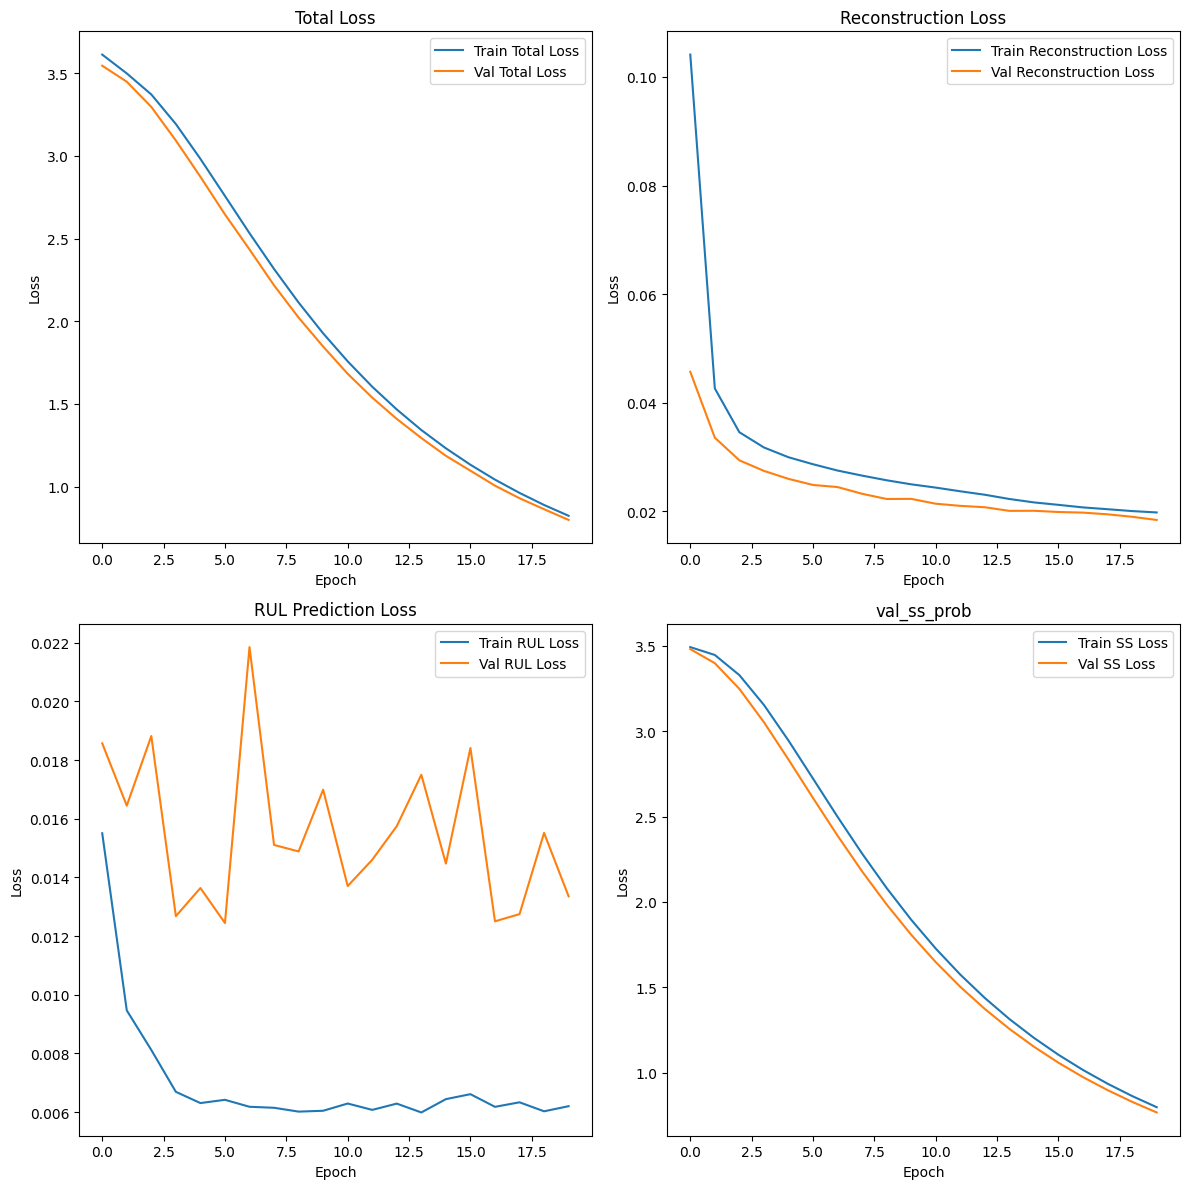

555/555 [==============================] - 1s 1ms/step


In [ ]:
def dataHandling(df, idName = 'id', sensors_used=None):
    if sensors_used is None: 
        sensors_used    = ['s2','s3','s4','s7','s8','s9','s11','s12','s13','s14','s15','s17','s20','s21']
        # sensors_used        = ['s1', 's2','s3','s4',"s5", "s6",'s7','s8','s9',"s10",'s11','s12','s13','s14','s15',"s16",'s17',"s18","s19",'s20','s21']
        
    
    window_size     = 30  # Fixed sequence length
    X_windows       = []
    engine_ids      = []
    start_cycles    = []

    # Build sliding windows from each engine
    for eng_id in df[idName].unique():
        # df_eng      = df[df[idName] == eng_id].sort_values('cycle')
        df_eng      = df[df[idName] == eng_id]
        data_eng    = df_eng[sensors_used].values
        for start in range(0, len(data_eng) - window_size + 1):
            window = data_eng[start : start + window_size]
            X_windows.append(window)
            engine_ids.append(eng_id)
            start_cycles.append(start + 1)

    X_windows = np.array(X_windows)  # (N, 30, 14)
    print(X_windows.shape)
    # Normalize
    N, seq_len, num_feats   = X_windows.shape
    X_flat                  = X_windows.reshape(N * seq_len, num_feats)
    scaler                  = MinMaxScaler()
    X_flat_scaled           = scaler.fit_transform(X_flat)
    X_scaled                = X_flat_scaled.reshape(N, seq_len, num_feats)
    return X_scaled, engine_ids, start_cycles, seq_len, num_feats

X_scaled, engine_ids, start_cycles, seq_len, num_feats  = dataHandling(df)
y_rul, _, _, _, _                                       = dataHandling(df, sensors_used=['rul'])  # Get RUL data
y_rul   = y_rul[:,-1,:]  # Get last value of each sequence

# ------------------------------------
# Sensor selection
# ------------------------------------
class SensorSelection(tf.keras.layers.Layer):
    def __init__(self, inFeature = 45, numEnvs = 3):
        '''
        The input size should be (batchSize, timeStep, featureDim)        
        '''
        super(SensorSelection, self).__init__()
        self.mask_logits    = self.add_weight(  shape       =   (inFeature,),  # Each mode has different sensor probabilities
                                                initializer =   "random_normal",
                                                trainable   =   True,
                                                name        =   "sensorMask")
                                            
    def call(self,rawData):
        # ----------------------------------
        # Select the environment
        # ----------------------------------
        # env                 = tf.cast(env, tf.int32)                                # Ensure integer type for indexing, and env from 1 to three, so we need index from 0 to 2
        # env_mask_logits     = tf.gather(self.mask_logits, env, axis=0)              # (batch_size, num_sensors) each sequence (after split) will have a different env, so env should be a batch (include differnt env to access to the mask)                    
    
        probs               = tf.sigmoid(self.mask_logits)
        random_uniform      = tf.random.uniform(tf.shape(probs))
        binary_mask         = tf.cast(tf.less(random_uniform, probs), tf.float32)

        maskedData          = rawData * probs
        # ----------------------------------
        # Add loss function for sensor selection
        sSLoss = tf.reduce_sum(probs * (1 - probs))
        self.add_loss(sSLoss)
        self.add_metric(sSLoss, name="ss_prob", aggregation="mean")
        return maskedData, probs, binary_mask
    
    def getMask(self,):
        probs               = tf.sigmoid(self.mask_logits)   
        random_uniform      = tf.random.uniform(tf.shape(probs))
        binary_mask         = tf.cast(tf.less(random_uniform, probs), tf.float32) 
        return binary_mask, probs

# print("----------------------------")
# print(num_feats,len(sensors_used))

Masking        = SensorSelection(   inFeature = len(sensors_used), 
                                    numEnvs   = 1)
# -----------------------------
# Encoder block
# -----------------------------
inputs                      = Input(shape=(seq_len, num_feats))
masked_input, mask_probs, _ = Masking(inputs)
x                           = Conv1D(32, 3, activation='relu', padding='same')(masked_input)
x                           = MaxPooling1D(2, padding='same')(x)
x                           = Conv1D(16, 3, activation='relu', padding='same')(x)
lastAELayer                 = MaxPooling1D(2, padding='same',name='lastAELayer')(x)
x                           = GlobalAveragePooling1D()(lastAELayer)
latent                      = Dense(1, name='latent')(x)  # HI directly here

print("The shape of last layer encoder is", lastAELayer.shape)

# -----------------------------
# Decoder block
# -----------------------------
x           = Dense((seq_len // 4) * 16, activation='relu')(latent)  # (7 * 16)
x           = Reshape((seq_len // 4, 16))(x)  # Shape: (7, 16)
x           = UpSampling1D(2)(x)  # Shape: (14, 16)
x           = Conv1D(32, 3, activation='relu', padding='same')(x)  # Shape: (14, 32)
x           = UpSampling1D(2)(x)  # Shape: (28, 32)
x           = ZeroPadding1D(padding=(1, 1))(x)  # Pad to get (30, 32)
decoded     = Conv1D(num_feats, 3, activation='linear', padding='same')(x)  # Shape: (30, 14)

print("---------------------------")
print(mask_probs.shape)
print(decoded.shape)
print("---------------------------")

masked_decoded  = tf.keras.layers.Multiply(name='reconstruction')([decoded, tf.reshape(mask_probs, (1, 1, -1))])

recon_loss      = tf.reduce_mean(tf.abs(masked_decoded - masked_input))
# -----------------------------
# Use RUL as label
# -----------------------------
if useRUL:
    rulLayer2   = LSTM(16, return_sequences=True)(lastAELayer)
    rulLayer3   = LSTM(3, return_sequences=False)(rulLayer2)
    flipped_latent = Lambda(lambda x: -x)(latent)  # force decreasing trend
    rulLayer4   = Concatenate(axis=-1)([rulLayer3, flipped_latent])

    rul         = Dense(1, activation='linear', name="RUL_Output")(rulLayer4)
    cnn_ae      = Model(inputs, outputs=[masked_decoded, rul])


    cnn_ae.add_loss(recon_loss)
    cnn_ae.add_metric(recon_loss, name="recon_loss", aggregation="mean")
    cnn_ae.compile(optimizer    ='adam', 
                   loss         ={ 'RUL_Output': 'mse'},
                   loss_weights ={ 'RUL_Output': 1})  # adjust weights as needed
else:
    # If not using RUL, just use the masked decoded output
    cnn_ae = Model(inputs, outputs=[masked_decoded])
    cnn_ae.add_loss(recon_loss)
    cnn_ae.add_metric(recon_loss, name="recon_loss", aggregation="mean")
    cnn_ae.compile(optimizer='adam')

print(cnn_ae.output_names)  # ['reconstruction']
print(cnn_ae.metrics_names) # ['loss', 'mae', 'ss_prob']

if useRUL:
    history = cnn_ae.fit(X_scaled, {'RUL_Output': y_rul},
                        epochs=epochTrain, batch_size=128, validation_split=0.1, verbose=1)
    print(history.history.keys())


    plt.figure(figsize=(12, 12))

    plt.subplot(2, 2, 1)
    plt.plot(history.history['loss'], label='Train Total Loss')
    plt.plot(history.history['val_loss'], label='Val Total Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Total Loss')
    plt.legend()

    # --- Plot reconstruction loss ---
    plt.subplot(2, 2, 2)
    plt.plot(history.history['recon_loss'], label='Train Reconstruction Loss')
    plt.plot(history.history['val_recon_loss'], label='Val Reconstruction Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Reconstruction Loss')
    plt.legend()

    # --- Plot RUL prediction loss ---
    plt.subplot(2, 2, 3)
    plt.plot(history.history['RUL_Output_loss'], label='Train RUL Loss')
    plt.plot(history.history['val_RUL_Output_loss'], label='Val RUL Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('RUL Prediction Loss')
    plt.legend()


    plt.subplot(2, 2, 4)
    plt.plot(history.history['ss_prob'], label='Train SS Loss')
    plt.plot(history.history['val_ss_prob'], label='Val SS Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('val_ss_prob')
    plt.legend()

    plt.tight_layout()
    plt.show()

else:
    cnn_ae.fit(X_scaled, {'reconstruction': X_scaled}, epochs=epochTrain, batch_size=128, validation_split=0.1, verbose=1)


# Extract latent HI values
encoder = Model(    inputs  =   cnn_ae.input,
                    outputs =   [cnn_ae.get_layer('lastAELayer').output, 
                                 cnn_ae.get_layer('latent').output],
                                name="encoder_submodel")

_, hi_values   = encoder.predict(X_scaled)
hi_values      = hi_values.flatten()  # Flatten to 1D array
# Normalize HI (optional)
hi_values = (hi_values - hi_values.min()) / (hi_values.max() - hi_values.min())

# Build dataframe for plotting
df_hi = pd.DataFrame({
    'id': engine_ids,
    'cycle': start_cycles,
    'HI': hi_values
})

# Plot first 20 engines
plt.figure(figsize=(10, 6))
for eng_id in df_hi['id'].unique()[:40]:
    df_eng = df_hi[df_hi['id'] == eng_id]
    plt.plot(df_eng['cycle'], df_eng['HI'], label=f'ID={eng_id}')
plt.xlabel("Cycle")
plt.ylabel("Health Index (Latent Value from CNN AE)")
plt.title("1D Latent HI from CNN Autoencoder (First 20 Engines)")
plt.legend(ncol=2, fontsize='small')
plt.tight_layout()
plt.show()

In [ ]:
from prettytable    import PrettyTable

binaryMask, mask_probs = Masking.getMask()
print(binaryMask.shape, mask_probs.shape)

ssTable                 = PrettyTable()
ssTable.field_names     = ["No","sensorName","probability", "binary"]
print(f"The number of selected sensor is {sum(binaryMask)}")
for idx,idxSS in enumerate(sensors_used):
    ssTable.add_row([idx,idxSS,mask_probs[idx].numpy(),binaryMask[idx].numpy()])

print(ssTable)





### DATA FOR SYSTEM MODEL

In [ ]:
def resize_group(g, targetLen, fill_value=0, id_col='trajectoryID', cycle_col='cycle'):
    currentLen  = len(g)
    pad_size    = targetLen - currentLen

    if pad_size == 0:
        return g
    elif pad_size < 0:
        return g.iloc[:targetLen].reset_index(drop=True)

    # Padding case: pad_size > 0
    lastCycle       = g[cycle_col].iloc[-1] if cycle_col in g.columns else currentLen - 1
    pad_df          = pd.DataFrame(fill_value, index=range(pad_size), columns=g.columns)
    pad_df[id_col]  = g[id_col].iloc[0]
    
    if cycle_col in g.columns:
        pad_df[cycle_col] = range(lastCycle + 1, lastCycle + pad_size + 1)

    return pd.concat([g, pad_df], ignore_index=True)


def createSystemData(inData, numberOfTrajectories=300, mode = "max"):
   
    rawData         = inData
    # --------------------------
    # Group the data into ID and
    # initiate the values
    # --------------------------
    grouped_data    = {k: v for k, v in rawData.groupby("id")}                                                          # Pre-group `rawData` by 'id' for O(1) lookup
    # createdData     = {}                                                                                                # Initialize dictionary for cases
    # --------------------------
    # Create system data
    # --------------------------
    selected_ids    = np.array([np.random.choice(np.arange(1, 101), size=3, replace=False) for _ in range(numberOfTrajectories)])     # Generate 400 sets of 3 unique trajectory IDs per iteration
    
    comp1_df        = pd.concat([grouped_data[i].assign(trajectoryID=trajectID + 1) for trajectID, i in enumerate(selected_ids[:, 0])], ignore_index=True) 
    comp2_df        = pd.concat([grouped_data[i].assign(trajectoryID=trajectID + 1) for trajectID, i in enumerate(selected_ids[:, 1])], ignore_index=True) 
    comp3_df        = pd.concat([grouped_data[i].assign(trajectoryID=trajectID + 1) for trajectID, i in enumerate(selected_ids[:, 2])], ignore_index=True)                    # Fetch data from grouped dictionary (guaranteed unique per iteration)
    


      

    lenEachIDComp1  = comp1_df.groupby("trajectoryID").size()
    lenEachIDComp2  = comp2_df.groupby("trajectoryID").size()
    lenEachIDComp3  = comp3_df.groupby("trajectoryID").size()
    lengths         = pd.concat([lenEachIDComp1, lenEachIDComp2, lenEachIDComp3], axis=1)
    lengths.columns = ['len1', 'len2', 'len3']

    dfRul           = pd.DataFrame(columns=["rul", "trajectoryID"])  
    if mode == 'min':
        minLen       = lengths.min(axis=1)
        comp1Handled = comp1_df.groupby('trajectoryID').apply(lambda g: g.iloc[:minLen[g.name]]).reset_index(drop=True)
        comp2Handled = comp2_df.groupby('trajectoryID').apply(lambda g: g.iloc[:minLen[g.name]]).reset_index(drop=True)
        comp3Handled = comp3_df.groupby('trajectoryID').apply(lambda g: g.iloc[:minLen[g.name]]).reset_index(drop=True)
        dfRul["rul"] = pd.concat([comp1Handled["rul"], comp2Handled["rul"], comp3Handled["rul"]], axis=1).min(axis=1)
    
    elif mode == 'max':
        minLen       = lengths.min(axis=1)
        comp1Handled = comp1_df.groupby('trajectoryID').apply(lambda g: g.iloc[:minLen[g.name]]).reset_index(drop=True)
        comp2Handled = comp2_df.groupby('trajectoryID').apply(lambda g: g.iloc[:minLen[g.name]]).reset_index(drop=True)
        comp3Handled = comp3_df.groupby('trajectoryID').apply(lambda g: g.iloc[:minLen[g.name]]).reset_index(drop=True)
        dfRul["rul"] = pd.concat([comp1Handled["rul"], comp2Handled["rul"], comp3Handled["rul"]], axis=1).max(axis=1)
    # elif mode == 'max':
    #     maxLen       = lengths.max(axis=1)
    #     comp1Handled = comp1_df.groupby('trajectoryID').apply(lambda g: resize_group(g, maxLen[g.name])).reset_index(drop=True)
    #     comp2Handled = comp2_df.groupby('trajectoryID').apply(lambda g: resize_group(g, maxLen[g.name])).reset_index(drop=True)
    #     comp3Handled = comp3_df.groupby('trajectoryID').apply(lambda g: resize_group(g, maxLen[g.name])).reset_index(drop=True)

    #     dfRul["rul"] = pd.concat([comp1Handled["rul"], comp2Handled["rul"], comp3Handled["rul"]], axis=1).max(axis=1)

    else:
        minLen          = lengths.min(axis=1)
        comp1Handled    = comp1_df.groupby('trajectoryID').apply(lambda g: g.iloc[:minLen[g.name]]).reset_index(drop=True)
        comp2Handled    = comp2_df.groupby('trajectoryID').apply(lambda g: g.iloc[:minLen[g.name]]).reset_index(drop=True)
        comp3Handled    = comp3_df.groupby('trajectoryID').apply(lambda g: g.iloc[:minLen[g.name]]).reset_index(drop=True)
        dfRul["rul"]    = comp1_df["rul"].combine(comp2_df["rul"], max).combine(comp3_df["rul"], min)
        # dfRul.to_excel('output.xlsx', index=False)  # index=False removes the row numbers
    dfRul["comp1"]  = comp1Handled["rul"]
    dfRul["comp2"]  = comp2Handled["rul"]                                                                # Initialize RUL dataframe
    dfRul["comp3"]  = comp3Handled["rul"]
    # else:
    #     linearLen    = lengths[['len1', 'len2']].max(axis=1).combine(lengths['len3'], func=min)
    #     comp1Handled = comp1_df.groupby('trajectoryID').apply(lambda g: resize_group(g, linearLen[g.name])).reset_index(drop=True)
    #     comp2Handled = comp2_df.groupby('trajectoryID').apply(lambda g: resize_group(g, linearLen[g.name])).reset_index(drop=True)
    #     comp3Handled = comp3_df.groupby('trajectoryID').apply(lambda g: resize_group(g, linearLen[g.name])).reset_index(drop=True)
    #     dfRul["rul"] = comp1_df["rul"].combine(comp2_df["rul"], max).combine(comp3_df["rul"], min)
    
    dfRul["trajectoryID"] = comp1Handled["trajectoryID"]      # Add trajectoryID to RUL data
    # dfRul.to_excel('dfRul.xlsx', index=False)  # index=False removes the row numbers
    # comp1Handled.to_excel('comp1Handled.xlsx', index=False)  # index=False removes the row numbers
    # comp2Handled.to_excel('comp2Handled.xlsx', index=False)  # index=False removes the row numbers
    # comp3Handled.to_excel('comp3Handled.xlsx', index=False)  # index=False removes the row numbers

    return comp1Handled, comp2Handled, comp3Handled, dfRul

def createRULLabel(inData, mode = "max"):
    if mode == 'min':
        sysRUL = inData.min(axis =2)
    elif mode == 'max':
        sysRUL = inData.max(axis =2)
    else:
        col1 = inData[:,:, 0]
        col2 = inData[:,:, 1]
        col3 = inData[:,:, 2]
        intermediate_max = np.maximum(col1, col2)
        sysRUL = np.minimum(intermediate_max, col3)

    # print(sysRUL.shape, sysRUL[:,-1,:].shape)
    return sysRUL[:,-1]
        


### Linear

In [ ]:

comp1, comp2, comp3, dfRul                  = createSystemData(df, numberOfTrajectories=300, mode=hiSelectionMode)  # Create system data
X_scaled1, engine_ids1, start_cycles1, _, _ = dataHandling(comp1,   idName='trajectoryID')
X_scaled2, engine_ids2, start_cycles2, _, _ = dataHandling(comp2,   idName='trajectoryID')
X_scaled3, engine_ids3, start_cycles3, _, _ = dataHandling(comp3,   idName='trajectoryID')
allRUL, _, _, _, _                          = dataHandling(dfRul,   idName='trajectoryID', sensors_used=['comp1', 'comp2', 'comp3'])  # Get RUL data
sysRUL                                      = createRULLabel(allRUL, mode = hiSelectionMode)
print(sysRUL.shape)

### System model

In [ ]:
encoder.summary()
for layer in encoder.layers:
    layer.trainable = False

In [ ]:
def selection_entropy_loss(y_true, y_pred):
    """
    y_pred: hiMatrixOutput -> shape (None, 3)
    We ignore y_true because we don't have a label for it.
    This returns the negative sum(p * log p).
    """
    # Add a small constant (1e-10) inside the log to avoid log(0).
    # The shape of this expression is (batch_size,).
    neg_entropy = -tf.reduce_sum(y_pred * tf.math.log(y_pred + 1e-10), axis=-1)
    return neg_entropy


In [ ]:


input1              = Input(shape=(seq_len, num_feats))
input2              = Input(shape=(seq_len, num_feats))
input3              = Input(shape=(seq_len, num_feats))

inputRUL1, HI1 = encoder(input1)
inputRUL2, HI2 = encoder(input2)
inputRUL3, HI3 = encoder(input3)

# --------------------------
# add more HI calibratio

# inputRUL1   = Input(shape=(8, 16),     name = "lastLayerAEComponent1")
# inputRUL2   = Input(shape=(8, 16),     name = "lastLayerAEComponent2")
# inputRUL3   = Input(shape=(8, 16),     name = "lastLayerAEComponent3")

# inputHI1    = Input(shape=(1,),     name = "compHI1")
# inputHI2    = Input(shape=(1,),     name = "compHI2")
# inputHI3    = Input(shape=(1,),     name = "compHI3")


flatInRUL1          = Flatten()(inputRUL1)  # Shape: (32, 40)
flatInRUL2          = Flatten()(inputRUL2)  # Shape: (32, 40)
flatInRUL3          = Flatten()(inputRUL3)  # Shape: (32, 40)
hiSelectionInput    = Concatenate(axis=-1)([flatInRUL1, flatInRUL2, flatInRUL3])

print(f"The shape of hiSelectionInput {hiSelectionInput.shape}")
# ------------------------------
# Create the HI selection matrix
# ------------------------------
x                   = Dense(24, activation="relu")(hiSelectionInput)
x                   = Dense(16, activation="relu")(x)
selection_logits    = Dense(3, activation=None, name="Selection_Logits")(x)
hiMatrixOutput      = Lambda(lambda x: tf.nn.softmax(x / 1), name="Selection_Output")(selection_logits)  # Softmax with τ=0.1 for sharper selection
print(f"The shape of multiplied matrix {hiMatrixOutput.shape}")

# ------------------------------
# Create min, max and linear HI
# ------------------------------
minSysHi   = Minimum()([HI1, HI2, HI3])
maxSysHi   = Maximum()([HI1, HI2, HI3])
linearSysHi   = Minimum()([Maximum()([HI1, HI2]), HI3])

# concatenatedHiInput = Concatenate(axis=-1)([inputHI1, inputHI2, inputHI3])
# minSysHi            = Minimum()([inputHI1, inputHI2, inputHI3])
# maxSysHi            = Maximum()([inputHI1, inputHI2, inputHI3]) 
# linearSysHi         = Minimum()([Maximum()([inputHI1, inputHI2]), inputHI3])

# print(f"The shape of min, max and linear HI {minSysHi.shape, maxSysHi.shape, linearSysHi.shape}")

sysConcatenatedHi   = tf.keras.layers.Concatenate(axis=-1, name="sysConcatenatedHi")([minSysHi, maxSysHi, linearSysHi])

print(f"The shape after concatenation {sysConcatenatedHi.shape}")
selected_HI         = Multiply(name="Selected_HI")([hiMatrixOutput, sysConcatenatedHi])

print(f"The shape after multiplying with mask {selected_HI.shape}")
sysHi               = Lambda(lambda x: tf.reduce_sum(x, axis=-1, keepdims=True), name="Final_HI")(selected_HI)            # Final HI (ensuring only one HI contributes to output)


# sysHi               = linearSysHi

print(f"The shape of HI after reducing dimension {sysHi.shape}")
# ------------------------------
# RUL
# ------------------------------
concatenatedRULInput = Concatenate(axis=-1)([inputRUL1, inputRUL2, inputRUL3])
print(f"The shape of concatenatedRULInput {concatenatedRULInput.shape}")
# concatenatedRULInput = Concatenate(axis=-1)([inputRUL1, inputRUL2])
rulLayer1   = LSTM(32, return_sequences=True)(concatenatedRULInput)
rulLayer2   = LSTM(16, return_sequences=True)(rulLayer1)
rulLayer3   = LSTM(3, return_sequences=False)(rulLayer2)
rulLayer4   = Concatenate(axis=-1)([rulLayer3, sysHi])
rul         = tf.keras.layers.Dense(1, activation='linear', name = "RUL_Output")(rulLayer4)

# Create the model
sysModel = Model(inputs=[input1, input2, input3], outputs=[hiMatrixOutput, sysHi,rul])

sysModel.compile(optimizer  =       'adam',
                loss        =   {   "Selection_Output"  : selection_entropy_loss,
                                    "Final_HI"          : "mse",
                                    "RUL_Output"        : "mse"},
                loss_weights=   {   "Selection_Output"  : 0.1,  # e.g. a small coefficient
                                    "Final_HI"          : 0.0,  # no label for HI => set to 0 or 0.01 if you want
                                    "RUL_Output"        : 1.0},      
                )

sysModel.summary()

dummy_sel = np.zeros_like(sysRUL)
sysModel.fit([X_scaled1, X_scaled2, X_scaled3], [dummy_sel,dummy_sel,sysRUL], epochs=sysEpoch, batch_size=128, validation_split=0.1, verbose=1)


In [ ]:
_, hi_values1   = encoder.predict(X_scaled1)
hi_values1      = hi_values1.flatten()  # Flatten to 1D array

_, hi_values2   = encoder.predict(X_scaled2)
hi_values2      = hi_values2.flatten()  # Flatten to 1D array

_, hi_values3   = encoder.predict(X_scaled3)
hi_values3      = hi_values3.flatten()  # Flatten to 1D array

[hiMatrixOutput, sysHi, rul] = sysModel.predict([X_scaled1, X_scaled2, X_scaled3])


In [ ]:
print(hiMatrixOutput)

In [ ]:
# Build dataframe for plotting
df_hi = pd.DataFrame({
    'id'    : engine_ids1,
    'cycle' : start_cycles1,
    'HI1'    : hi_values1,
    'HI2'    : hi_values2,
    'HI3'    : hi_values3,
    'sysHI'  : sysHi.flatten(),
    "sysRUL": rul.flatten(),
    "labelSysRUL": sysRUL.flatten(),
    "comp1RUL": allRUL[:,-1,0].flatten(),
    "comp2RUL": allRUL[:,-1,1].flatten(),
    "comp3RUL": allRUL[:,-1,2].flatten()
})

In [ ]:
import matplotlib.pyplot as plt
import math

num_cols = 5  # number of plots per row
num_rows = math.ceil(drawTrajectories / num_cols)

fig, axes = plt.subplots(num_rows, num_cols, figsize=(20, num_rows * 2.5), sharex=False, sharey=False)
axes = axes.flatten()  # Flatten to 1D array for easy indexing

for i, eng_id in enumerate(df_hi['id'].unique()[:drawTrajectories]):
    ax = axes[i]
    df_eng = df_hi[df_hi['id'] == eng_id]
    
    ax.plot(df_eng['cycle'], df_eng["HI1"], label="Comp1")
    ax.plot(df_eng['cycle'], df_eng["HI2"], label="Comp2")
    ax.plot(df_eng['cycle'], df_eng["HI3"], label="Comp3")
    ax.plot(df_eng['cycle'], df_eng["sysHI"], label="Sys")
    
    ax.set_title(f"Engine {eng_id}", fontsize=8)
    ax.tick_params(axis='both', labelsize=6)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Add a big legend outside the subplots
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=4, fontsize='small')

fig.suptitle("Health Indices per Engine (1D Latent HI from CNN AE)", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])  # leave space for suptitle and legend
plt.show()


In [ ]:
num_cols            = 5  # number of plots per row
num_rows            = math.ceil(drawTrajectories / num_cols)

fig, axes           = plt.subplots(num_rows, num_cols, figsize=(20, num_rows * 2.5), sharex=False, sharey=False)
axes                = axes.flatten()  # Flatten to 1D array for easy indexing

for i, eng_id in enumerate(df_hi['id'].unique()[:drawTrajectories]):
    ax      = axes[i]
    df_eng  = df_hi[df_hi['id'] == eng_id]
    ax.plot(df_eng['cycle'], df_eng["comp1RUL"], label="Comp1")
    ax.plot(df_eng['cycle'], df_eng["comp2RUL"], label="Comp2")
    ax.plot(df_eng['cycle'], df_eng["comp3RUL"], label="Comp3")
    ax.plot(df_eng['cycle'], df_eng["labelSysRUL"], label="CompSys")
    ax.set_title(f"Engine {eng_id}", fontsize=8)
    ax.tick_params(axis='both', labelsize=6)


# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Add a big legend outside the subplots
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=4, fontsize='small')

fig.suptitle("Health Indices per Engine (1D Latent HI from CNN AE)", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])  # leave space for suptitle and legend
plt.show()

In [ ]:
num_cols            = 5  # number of plots per row
num_rows            = math.ceil(drawTrajectories / num_cols)

fig, axes           = plt.subplots(num_rows, num_cols, figsize=(20, num_rows * 2.5), sharex=False, sharey=False)
axes                = axes.flatten()  # Flatten to 1D array for easy indexing

for i, eng_id in enumerate(df_hi['id'].unique()[:drawTrajectories]):
    ax      = axes[i]
    df_eng  = df_hi[df_hi['id'] == eng_id]

    
    ax.plot(df_eng['cycle'], df_eng["sysRUL"], label="Comp1")
    ax.set_title(f"Engine {eng_id}", fontsize=8)
    ax.tick_params(axis='both', labelsize=6)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Add a big legend outside the subplots
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=4, fontsize='small')

fig.suptitle("Health Indices per Engine (1D Latent HI from CNN AE)", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])  # leave space for suptitle and legend
plt.show()
